# 04 Image Features

This notebook turns each image into numbers (features) that help spot edited faces.
- **face_swap:** someone else's face is pasted in.
- **face_attribute:** the face's expression is changed by an AI model.

**Main idea:** compare each face with the area around it (a "ring"). Edited faces often look smoother or noisier than their surroundings.

Features use only the image and its face boxes. Labels, file paths and captions are never used.

| Section | What it does |
|---|---|
| 1 How we make each feature | the 4 filters on a real photo and its edited version |
| 2 Make the features for every image | computes and saves the features |
| 3 Shortcut checks | finds features that only work because of how the dataset was made, and removes them |

## 0. Setup

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = PROJECT_ROOT / "data" / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train_sample", "validation", "test"]
RANDOM_STATE = 4012

sns.set_theme(style="whitegrid")

In [2]:
data = {split: pd.read_parquet(PROCESSED_DIR / f"{split}.parquet") for split in SPLITS}
pd.Series({split: len(df) for split, df in data.items()}, name="rows")

train_sample    49943
validation      22126
test            50705
Name: rows, dtype: int64

In [3]:
def save_features(features, group, allow_missing=False):
    """Save one feature group per split. `features` must have a row_id column covering every row of each split.
    allow_missing=True keeps NaN (used for face features of images without a usable face; models impute them)."""
    for split, df in data.items():
        split_features = df[["row_id"]].merge(features, on="row_id", how="left")
        assert len(split_features) == len(df), f"{group}: row count changed for {split}"
        if not allow_missing:
            assert split_features.drop(columns="row_id").notna().all().all(), f"{group}: missing values for {split}"
        path = FEATURES_DIR / f"{group}_{split}.parquet"
        split_features.to_parquet(path, index=False)
        print(f"{path.relative_to(PROJECT_ROOT)}  {split_features.shape}")


def univariate_auc(features, target, label_df=None):
    """ROC-AUC of each feature on its own against a binary target, on train_sample only.
    0.5 = no signal. Values far from 0.5 in either direction mean the feature separates the classes.
    A value near 0 or 1 for a simple feature is a red flag for leakage or a dataset shortcut."""
    label_df = data["train_sample"] if label_df is None else label_df
    merged = label_df[["row_id", target]].merge(features, on="row_id")
    feature_cols = [c for c in features.columns if c != "row_id"]
    aucs = pd.Series({c: roc_auc_score(merged[target], merged[c]) for c in feature_cols}, name=f"AUC vs {target}")
    return aucs.to_frame().assign(strength=(aucs - 0.5).abs()).sort_values("strength", ascending=False).drop(columns="strength")

In [4]:
# Text-only fakes reuse the original image, so image features are computed once per distinct image and joined back
all_rows = pd.concat(data.values(), ignore_index=True)
print(f"{len(all_rows):,} rows, {all_rows['image'].nunique():,} distinct images")


122,774 rows, 110,030 distinct images


## 1. How We Make Each Feature

We run 4 filters on one real photo (top row) and its edited version (bottom row).
- Red box: the edited face. Blue: other faces. Dashed: the ring around each face.
- Colours are brightened for display only; the features use the raw values.

**From picture to numbers.** For each face we record:
- `_face`: the average inside the face
- `_ratio`: face ÷ ring (1 = the face looks like its surroundings)
- `_p90ratio`: the same, using the brightest 10% of pixels, so small sharp details are not averaged away

Then across all faces in the photo we keep the `_max`, `_min`, `_mean`, the `_largest` face, and the `_spread` (the gap between faces).

One example pair is not proof that a filter works; it just shows what each filter does.

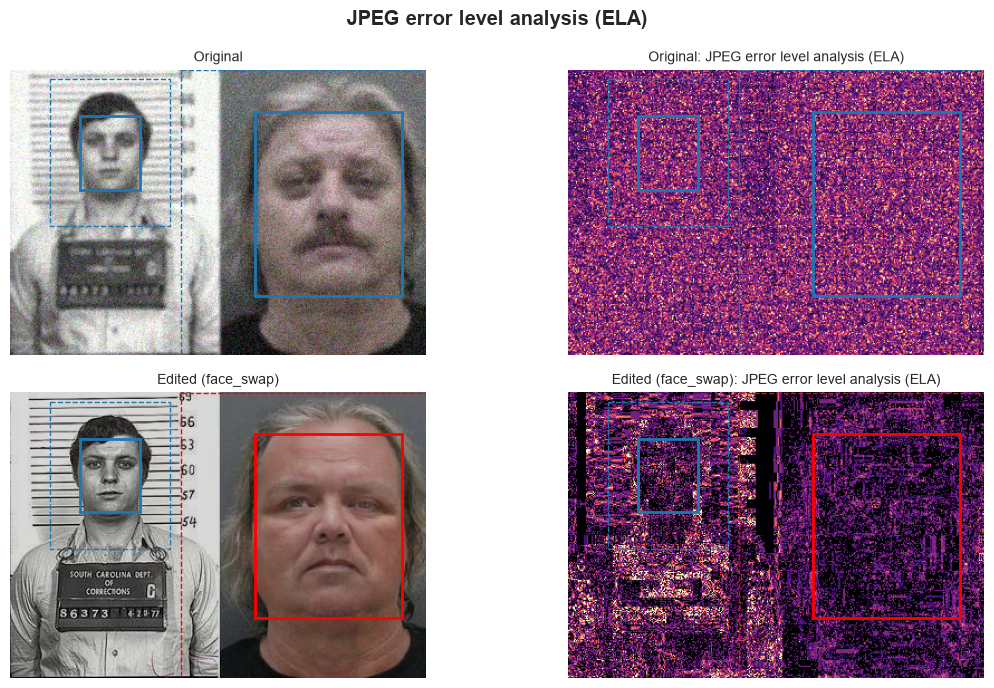

What it shows: Bright = changed a lot when the photo was re-saved. A pasted-in face can stand out.
Features: img_ela_mean, img_ela_face_*, img_ela_ratio_*


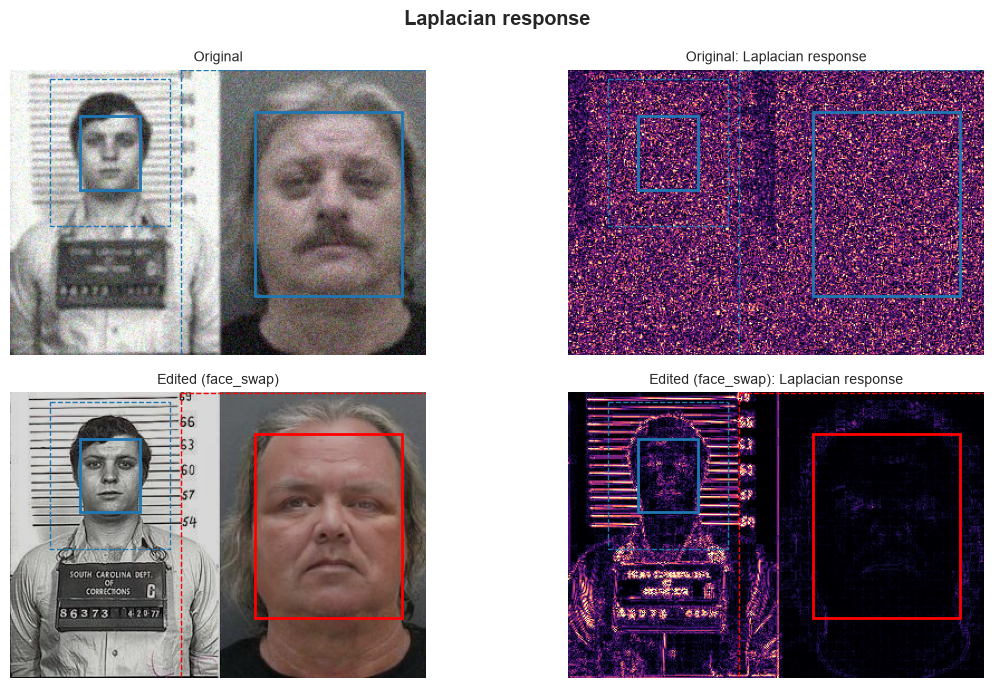

What it shows: Bright = sharp edges and fine detail. An edited face often looks darker (smoother) than the area around it.
Features: img_lap_mean, img_lap_face_*, img_lap_ratio_*, img_lap_p90ratio_*


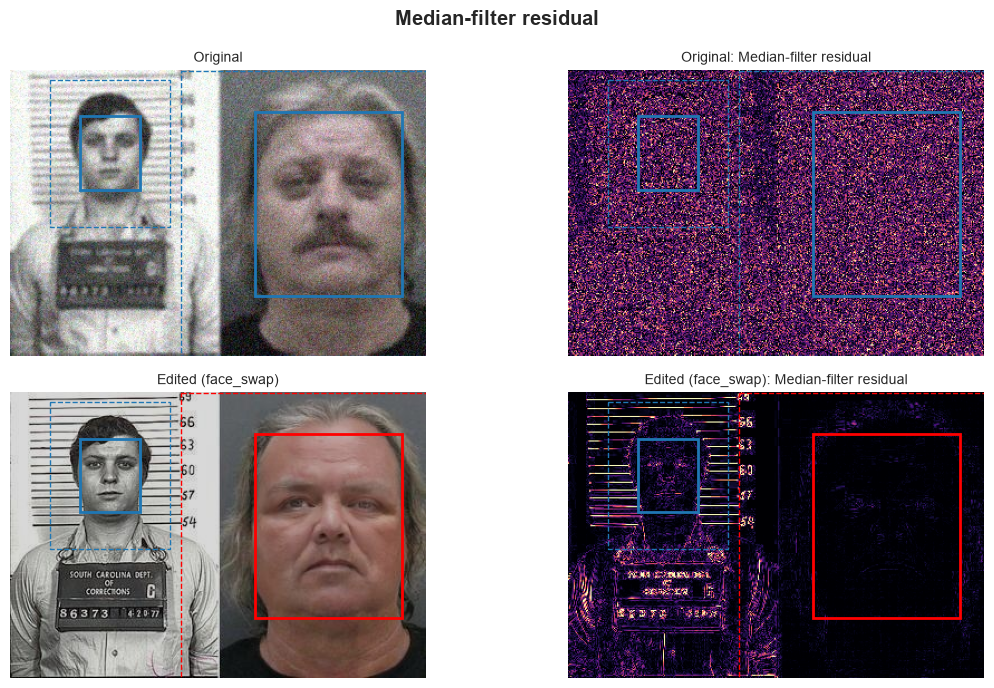

What it shows: Bright = fine noise. A face taken from another photo can have a different noise level.
Features: img_noise_mean, img_noise_face_*, img_noise_ratio_*, img_noise_p90ratio_*


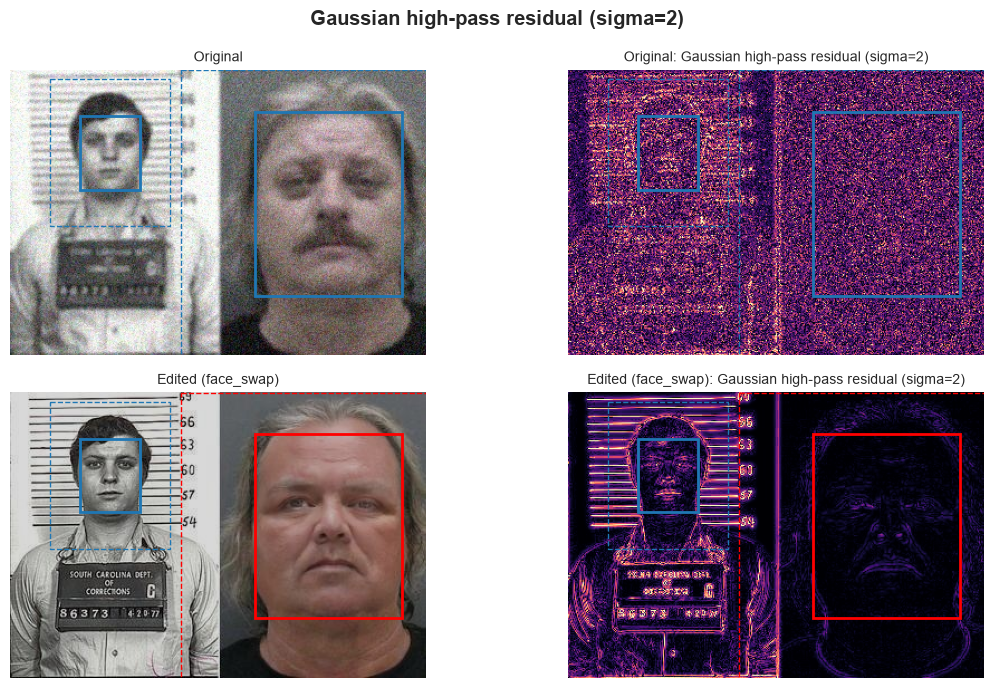

What it shows: Bright = skin and hair texture. A computer-generated face often looks flatter.
Features: img_gauss_ratio_*


In [5]:
from matplotlib.patches import Rectangle
from src.image_features import FILTERS, face_regions
from src.images import load_image

# One face_swap image and the original photo of the same article
swap_row = data["train_sample"][data["train_sample"]["fake_cls"] == "face_swap"].sample(1, random_state=7).iloc[0]
orig_row = data["train_sample"][(data["train_sample"]["id"] == swap_row["id"]) & (data["train_sample"]["fake_cls"] == "orig")].iloc[0]
examples = [("Original", orig_row, load_image(orig_row["image"])), ("Edited (face_swap)", swap_row, load_image(swap_row["image"]))]

# The feature columns each filter produces (absolute ELA columns are a dataset shortcut, see section 3)
FEATURES_FROM = {
    "ela": "img_ela_mean, img_ela_face_*, img_ela_ratio_*",
    "lap": "img_lap_mean, img_lap_face_*, img_lap_ratio_*, img_lap_p90ratio_*",
    "noise": "img_noise_mean, img_noise_face_*, img_noise_ratio_*, img_noise_p90ratio_*",
    "gauss": "img_gauss_ratio_*",
}


def draw_faces(ax, row, size):
    for box in row["mtcnn_boxes"]:
        regions = face_regions(box, *size)
        if regions is None:
            continue
        (x1, y1, x2, y2), (ox1, oy1, ox2, oy2) = regions
        edited = len(row["fake_image_box"]) and list(box) == list(row["fake_image_box"])
        color = "red" if edited else "tab:blue"
        ax.add_patch(Rectangle((ox1, oy1), ox2 - ox1, oy2 - oy1, fill=False, edgecolor=color, linewidth=1, linestyle="--"))
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))


for name, spec in FILTERS.items():
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for (label, row, image), (ax_image, ax_map) in zip(examples, axes):
        response = spec["map"](image)  # the raw map, exactly as the features use it
        ax_image.imshow(image)
        ax_image.set_title(label, fontsize=10)
        ax_map.imshow(response, cmap="magma", vmin=0, vmax=np.percentile(response, 99))  # display stretch only
        ax_map.set_title(f"{label}: {spec['title']}", fontsize=10)
        for ax in (ax_image, ax_map):
            draw_faces(ax, row, image.size)
            ax.axis("off")
    fig.suptitle(spec["title"], fontweight="bold")
    plt.tight_layout()
    plt.show()
    print(f"What it shows: {spec['meaning']}")
    print(f"Features: {FEATURES_FROM[name]}")

## 2. Make the Features for Every Image

We compute the features for every image and save two files:
- `image`: 35 features
- `image_filters`: 10 new features, the brightest-10% ratios and the texture ratio

Captions are ignored, so photos that appear in several rows are processed once.

In [6]:
from concurrent.futures import ProcessPoolExecutor
from src.image_features import image_features_safe

# Text-only fakes reuse the original image, so compute once per distinct image
images = all_rows.drop_duplicates("image")[["image", "mtcnn_boxes"]]
items = [(path, [[int(v) for v in box] for box in boxes]) for path, boxes in zip(images["image"], images["mtcnn_boxes"])]
print(f"{len(items):,} distinct images")

N_WORKERS = max(1, (os.cpu_count() or 2) - 2)
start = time.time()
with ProcessPoolExecutor(N_WORKERS) as pool:
    image_results = pd.DataFrame(pool.map(image_features_safe, items, chunksize=64))
print(f"{N_WORKERS} workers: {time.time() - start:.0f}s")

errors = image_results["error"].notna()
print("Images that failed:", int(errors.sum()))
assert not errors.any(), image_results.loc[errors, ["image", "error"]].head()

110,030 distinct images


8 workers: 309s
Images that failed: 0


In [7]:
image_features = (
    all_rows[["row_id", "image"]]
    .merge(image_results.drop(columns="error"), on="image", how="left")
    .drop(columns="image")
)
print(image_features.shape)
image_features.drop(columns="row_id").describe().T.round(3)

(122774, 36)


,count,mean,std,min,25%,50%,75%,max
img_width,122774.0,449.267,166.043,180.000,384.000,426.000,426.000,5353.000
img_height,122774.0,289.781,104.940,180.000,256.000,256.000,261.000,3958.000
img_n_faces,122774.0,2.673,0.934,2.000,2.000,2.000,3.000,5.000
img_ela_mean,122774.0,1.605,1.327,0.019,0.754,1.037,1.792,5.329
img_lap_mean,122774.0,16.294,13.274,0.089,5.452,12.618,22.544,112.196
img_noise_mean,122774.0,3.023,2.695,0.005,0.927,2.189,4.187,25.972
img_face_area_max,122774.0,0.050,0.059,0.003,0.016,0.029,0.057,0.672
img_face_area_mean,122774.0,0.038,0.046,0.002,0.012,0.022,0.043,0.633
img_ela_face_max,122774.0,2.018,1.333,0.207,1.075,1.436,2.592,5.967
img_ela_face_min,122774.0,1.731,1.331,0.089,0.865,1.135,2.075,5.413


In [8]:
from src.image_features import FILTER_COLUMNS, filter_features_safe

start = time.time()
with ProcessPoolExecutor(N_WORKERS) as pool:
    filter_results = pd.DataFrame(pool.map(filter_features_safe, items, chunksize=64))
print(f"{N_WORKERS} workers: {time.time() - start:.0f}s")
errors = filter_results["error"].notna()
print("Images that failed:", int(errors.sum()))
assert not errors.any(), filter_results.loc[errors, ["image", "error"]].head()

filter_table = (all_rows[["row_id", "image"]].merge(filter_results.drop(columns="error"), on="image", how="left")
                .drop(columns="image"))
assert list(filter_table.columns) == ["row_id", *FILTER_COLUMNS]
print(filter_table.shape, "| images without a usable face:", int(filter_table[FILTER_COLUMNS].isna().any(axis=1).sum()))
filter_table.drop(columns="row_id").describe().T.round(3)

8 workers: 357s
Images that failed: 0
(122774, 11) | images without a usable face: 0


,count,mean,std,min,25%,50%,75%,max
img_lap_p90ratio_min,122774.0,0.821,0.230,0.056,0.667,0.824,0.986,3.556
img_lap_p90ratio_max,122774.0,1.175,0.363,0.223,0.990,1.101,1.308,10.000
img_lap_p90ratio_largest,122774.0,0.971,0.324,0.102,0.773,0.964,1.100,9.000
img_noise_p90ratio_min,122774.0,0.932,0.252,0.103,0.762,1.000,1.000,6.111
img_noise_p90ratio_max,122774.0,1.312,0.401,0.250,1.000,1.231,1.500,10.000
img_noise_p90ratio_largest,122774.0,1.092,0.359,0.103,0.900,1.000,1.250,10.000
img_gauss_ratio_min,122774.0,0.901,0.253,0.133,0.732,0.885,1.030,3.799
img_gauss_ratio_max,122774.0,1.292,0.403,0.311,1.032,1.210,1.469,9.439
img_gauss_ratio_largest,122774.0,1.072,0.351,0.133,0.850,1.018,1.230,9.439
img_gauss_ratio_spread,122774.0,0.358,0.280,0.000,0.139,0.300,0.512,2.811


In [9]:
save_features(image_features, "image")
save_features(filter_table, "image_filters", allow_missing=True)

data/features/image_train_sample.parquet  (49943, 36)


data/features/image_validation.parquet  (22126, 36)
data/features/image_test.parquet  (50705, 36)
data/features/image_filters_train_sample.parquet  (49943, 11)
data/features/image_filters_validation.parquet  (22126, 11)


data/features/image_filters_test.parquet  (50705, 11)


## 3. Shortcut Checks: Features We Remove

Some features can tell real from fake only because of how the dataset was made, not because a face was edited. A model using them would not work on real news. We check for these and remove them.
- **Check 1, file size and quality:** do edited images have a different size or JPEG quality from their originals?
- **Check 2, every news site:** does a feature work for all 4 news sites, or only one?

In [10]:
from src.images import load_image

orig_rows = data["train_sample"][data["train_sample"]["fake_cls"] == "orig"].drop_duplicates("id")
check_ids = orig_rows["id"].sample(300, random_state=RANDOM_STATE)
check = data["train_sample"][
    data["train_sample"]["id"].isin(check_ids)
    & ((data["train_sample"]["fake_cls"] == "orig") | (data["train_sample"]["image_fake"] == 1))
].drop_duplicates("image")


def file_properties(image_path):
    image = load_image(image_path, convert=False)
    return {"size": image.size, "jpeg_quant_table": tuple(image.quantization[0])}


props = pd.DataFrame([file_properties(p) for p in check["image"]], index=check["image"].values)
check = check.join(props, on="image")

originals = check[check["fake_cls"] == "orig"].set_index("id")
fakes = check[check["image_fake"] == 1].copy()
fakes["same_size_as_original"] = fakes["size"] == fakes["id"].map(originals["size"])
fakes["same_jpeg_quality_as_original"] = fakes["jpeg_quant_table"] == fakes["id"].map(originals["jpeg_quant_table"])
fakes.groupby("image_source")[["same_size_as_original", "same_jpeg_quality_as_original"]].mean()

,same_size_as_original,same_jpeg_quality_as_original
image_source,,
manipulation/HFGI,1.0,1.0
manipulation/StyleCLIP,1.0,1.0
manipulation/infoswap,1.0,1.0
manipulation/simswap,1.0,1.0


**Check 1: file size and quality.** Edited images have exactly the same size and quality as their originals, so nothing to remove.

In [11]:
# Single-feature AUC per publisher, on distinct train_sample images (0.5 = no signal; far from 0.5 either way = signal).
# Manipulated files carry no publisher in their path, so each fake takes the publisher of its article's original.
all_features = image_features.merge(filter_table, on="row_id")
image_rows = data["train_sample"][["row_id", "id", "fake_cls", "image", "image_fake", "image_source"]].merge(all_features, on="row_id")
image_rows = image_rows.drop_duplicates("image")
publisher = image_rows[image_rows["fake_cls"] == "orig"].set_index("id")["image_source"].str.removeprefix("origin/")
image_rows["publisher"] = image_rows["id"].map(publisher)
image_rows = image_rows.dropna(subset=["publisher"])

img_cols = [c for c in all_features.columns if c.startswith("img_")]
by_publisher = pd.DataFrame({
    pub: {c: roc_auc_score(g["image_fake"], g[c].fillna(g[c].median())) for c in img_cols}
    for pub, g in image_rows.groupby("publisher")
})
by_publisher["all"] = [roc_auc_score(image_rows["image_fake"], image_rows[c].fillna(image_rows[c].median())) for c in img_cols]
by_publisher.round(3).sort_values("all", key=lambda s: (s - 0.5).abs(), ascending=False).head(15)

,bbc,guardian,usa_today,washington_post,all
img_ela_face_largest,0.479,0.271,0.477,0.481,0.377
img_ela_face_mean,0.491,0.275,0.480,0.484,0.383
img_ela_face_min,0.473,0.285,0.477,0.477,0.383
img_ela_face_max,0.503,0.278,0.484,0.493,0.387
img_ela_mean,0.500,0.290,0.485,0.496,0.393
img_noise_ratio_largest,0.407,0.409,0.438,0.431,0.415
img_lap_p90ratio_largest,0.424,0.411,0.433,0.422,0.418
img_noise_p90ratio_largest,0.415,0.408,0.444,0.432,0.418
img_lap_ratio_largest,0.420,0.413,0.440,0.429,0.420
img_noise_ratio_min,0.421,0.425,0.448,0.446,0.430


**Check 2: does it work for every news site?** (AUC 0.5 = no signal; further from 0.5 = stronger)
- **Removed:** the plain ELA features (`img_ela_mean`, `img_ela_face_*`) only work for the Guardian (about 0.28 there, about 0.48 elsewhere). The dataset re-saved the Guardian fakes but not the Guardian originals, so these features spot "re-saved file", not "edited face". They are listed in `ARTIFACT_FEATURES` and not used.
- **Kept:** the face-vs-ring features work the same for all 4 sites.

# Summary

- **Saved:** `image` (35 features) and `image_filters` (10 features).
- **Made by:** 4 filters, each comparing every face with its ring.
- **Removed:** the plain ELA features, a dataset shortcut.
- **Used by:** `07` (both groups) and `10` (the `image` group).